In [2]:
# !pip install -q kagglehub

# بخش 2-1 و 2-2

/kaggle/input/uc-merced-land-use-dataset
/kaggle/input/uc-merced-land-use-dataset/UCMerced_LandUse/Images
Number of class: 21
classes:  ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


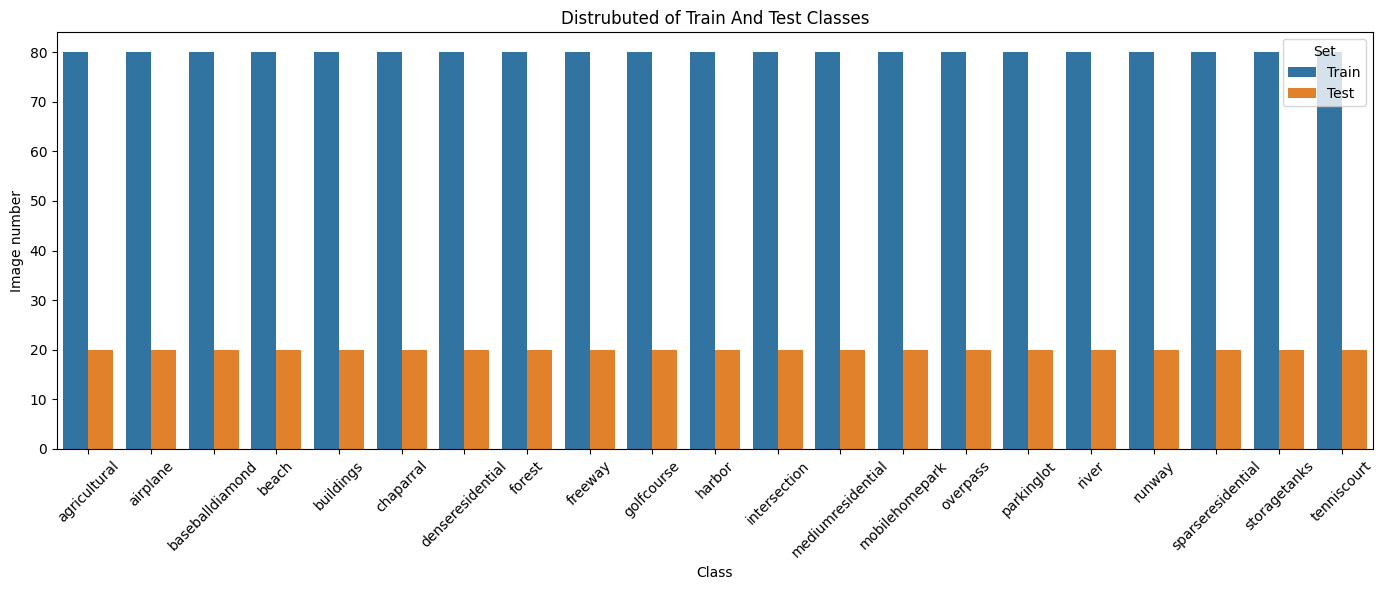

number of samples in train:1680
number of samples in train:420


In [3]:
import kagglehub
import pathlib
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from collections import Counter

import kagglehub

path = kagglehub.dataset_download("abdulhasibuddin/uc-merced-land-use-dataset")
print(path)
dataset_path = "/kaggle/input/uc-merced-land-use-dataset/UCMerced_LandUse/Images"
print(dataset_path)

from torchvision.datasets import ImageFolder
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor()
])

dataset = ImageFolder(root=dataset_path, transform=transform)
class_names = dataset.classes
print(f"Number of class: {len(class_names)}")
print("classes: ", class_names)

labels = [label for _, label in dataset.samples]
train_idx, test_idx = train_test_split(
    range(len(dataset)),
    test_size=0.2,
    stratify=labels,
    random_state=42
)

train_labels = [labels[i] for i in train_idx]
test_labels  = [labels[i] for i in test_idx]

train_counter = Counter(train_labels)
test_counter  = Counter(test_labels)

df = pd.DataFrame({
    'Class': [class_names[i] for i in range(len(class_names))],
    'Train': [train_counter.get(i, 0) for i in range(len(class_names))],
    'Test' : [test_counter.get(i, 0)  for i in range(len(class_names))]
}).melt(id_vars='Class', var_name='Split', value_name='Count')

plt.figure(figsize=(14, 6))
sns.barplot(data=df, x='Class', y='Count', hue='Split')
plt.title('Distrubuted of Train And Test Classes')
plt.xticks(rotation=45)
plt.ylabel('Image number')
plt.xlabel('Class')
plt.legend(title='Set')
plt.tight_layout()
plt.show()

print(f"number of samples in train:{len(train_idx)}")
print(f"number of samples in train:{len(test_idx)}")

numner of classes: 21


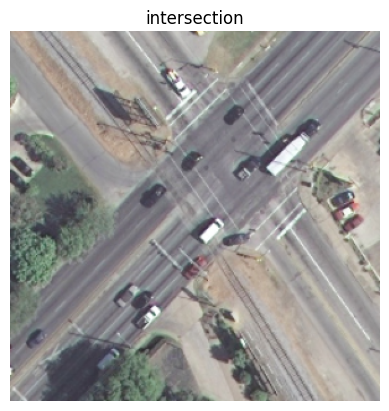

In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, models, datasets
from sklearn.model_selection import train_test_split
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


preprocess = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

data_dir =   dataset_path

full_dataset = datasets.ImageFolder(data_dir, transform=preprocess)
class_names = full_dataset.classes
print(f"numner of classes: {len(class_names)}")

labels = [label for _, label in full_dataset.samples]
train_idx, val_idx = train_test_split(
    range(len(full_dataset)),
    test_size=0.2,
    stratify=labels,
    random_state=42
)

train_dataset = Subset(full_dataset, train_idx)
val_dataset   = Subset(full_dataset, val_idx)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=2)


import random
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title:
        plt.title(title)
    plt.axis('off')

images, labels = next(iter(train_loader))
idx = random.randint(0, batch_size-1)
imshow(images[idx])
plt.title(f"{class_names[labels[idx]]}")
plt.show()

In [5]:
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as FU
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Dataset
import math
import random
def custom_augmentation(img):
    augmented_list = []

    augmented_list.append(img)
    augmented_list.append(FU.rotate(img, 90))
    augmented_list.append(FU.hflip(img))
    augmented_list.append(FU.vflip(img))
    augmented_list.append(FU.rotate(img, -90))
    g = FU.resize(img, [350, 350])
    augmented_list.append(FU.center_crop(g, [299, 299]))

    return augmented_list

def show_custom_augmentation_results(dataset, num_samples=2):
    titles = [
        'Original',
        '+90° Rotation',
        'Horizontal Flip',
        'Vertical Flip',
        '-90° Rotation',
        'Random Zoom'
    ]

    fig, axes = plt.subplots(num_samples, 6, figsize=(18, 6*num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, -1)

    for i in range(num_samples):
        image, label = dataset[random.randint(0, len(dataset))]

        augmented_images = custom_augmentation(image)

        for j, (aug_img, title) in enumerate(zip(augmented_images, titles)):
            if aug_img.dim() == 4:
                aug_img = aug_img.squeeze(0)

            img_np = aug_img.permute(1, 2, 0).numpy()
            img_np = np.clip(img_np, 0, 1)

            axes[i, j].imshow(img_np)
            axes[i, j].set_title(title, fontsize=10)
            axes[i, j].axis('off')

        axes[i, 0].set_ylabel(f'Class: {dataset.classes[label]}', fontsize=12)

    plt.suptitle('Custom Augmentation Results (6x Expansion)', fontsize=16)
    plt.tight_layout()
    plt.show()

    # Print statistics
    print(f"Generated {len(augmented_images)} augmented images per sample")
    print(f"Total expansion: {len(augmented_images)}x")
    print(f"Original dataset: {len(dataset)} images")
    print(f"Augmented dataset: {len(dataset) * len(augmented_images)} images")



preprocess = transforms.Compose([
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class AugmentedDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset) * 6

    def random_zoom(self, img):
        scale = random.uniform(1.0, 1.4)
        size = int(299 * scale)
        img = FU.resize(img, size=[size, size])
        
        img = FU.center_crop(img, (299, 299))
        return img

    def __getitem__(self, idx):
        original_idx = idx // 6
        aug_idx = idx % 6

        img, label = self.dataset[original_idx]
        if aug_idx == 0:
            aug = img
        elif aug_idx == 1:
            aug = FU.rotate(img, 90)
        elif aug_idx == 2:
            aug = FU.hflip(img)
        elif aug_idx == 3:
            aug = FU.vflip(img)
        elif aug_idx == 4:
            aug = FU.rotate(img, -90)
        elif aug_idx == 5:
            aug = self.random_zoom(img)
        img = preprocess(aug)
        return img, label

Original train dataset size: 1680 images
Combined augmented dataset size: 10080 images
Expansion factor: 6.0x


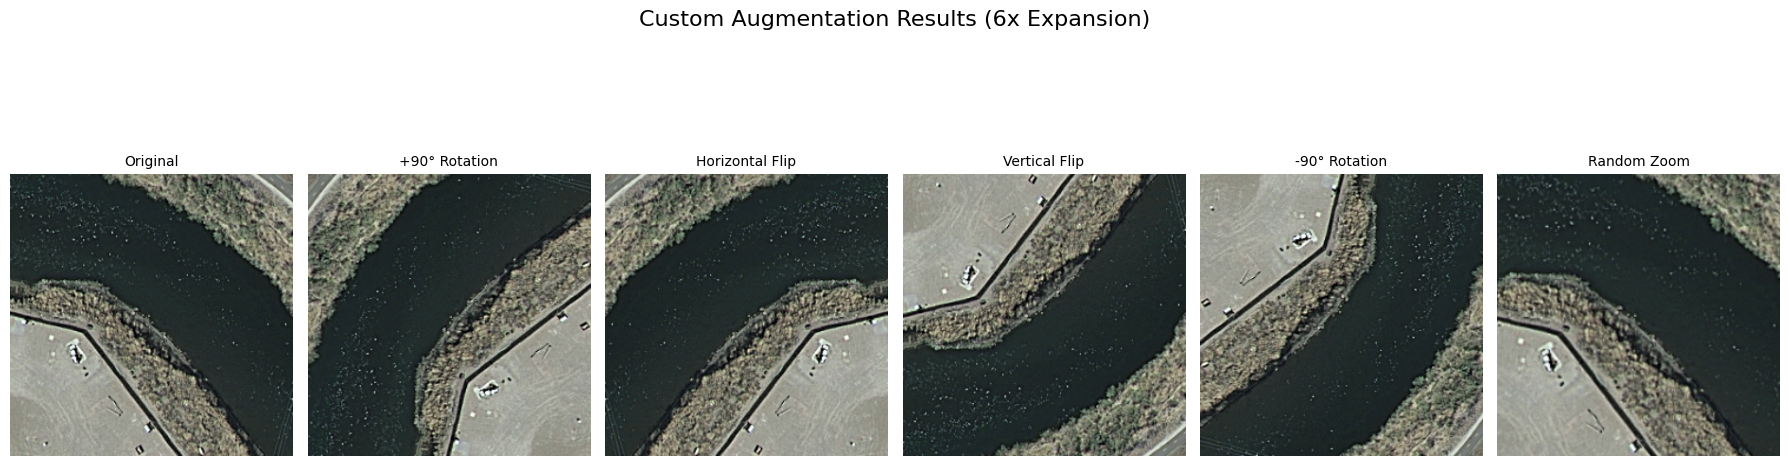

Generated 6 augmented images per sample
Total expansion: 6x
Original dataset: 2100 images
Augmented dataset: 12600 images


In [6]:
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, models, datasets
labels = [label for _, label in dataset.samples]
train_idx, val_idx = train_test_split(
    range(len(dataset)),
    test_size=0.2,
    stratify=labels,
    random_state=42
)

train_dataset = Subset(dataset, train_idx)
val_dataset   = Subset(dataset, val_idx)
normalize = transforms.Compose([
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


print(f"Original train dataset size: {len(train_dataset)} images")
combined_dataset = AugmentedDataset(train_dataset)

print(f"Combined augmented dataset size: {len(combined_dataset)} images")
print(f"Expansion factor: {len(combined_dataset) / len(train_dataset):.1f}x")
show_custom_augmentation_results(dataset, num_samples=1)
# images, labels = next(iter(combined_loader))

In [7]:
# !pip install timm

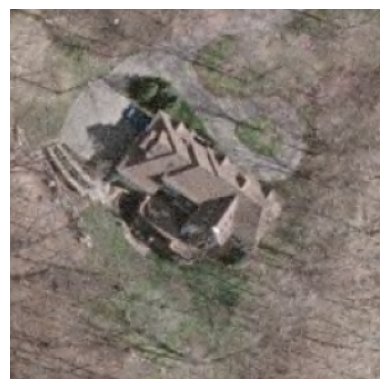

In [8]:
imshow(combined_dataset[5][0])
plt.show()
normalize = transforms.Compose([
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
# val_dataset.dataset.transform = normalize

# بخش 2-3 و 2-4

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import timm
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

PATH_OF_PRETRANED_MODEL = "/kaggle/input/xception-param/xception-43020ad28.pth"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
class XceptionMLP(nn.Module):
    def __init__(self, num_classes=21, dropout_rate=0.4, pretrained=False):
        super(XceptionMLP, self).__init__()
        self.device = None

        self.backbone = timm.create_model(
            'xception',
            pretrained=pretrained,
            checkpoint_path=None,
            num_classes=0,
            drop_rate=0.0
        )
        state_dict = torch.load(PATH_OF_PRETRANED_MODEL, map_location='cuda')
        missing, unexpected = self.backbone.load_state_dict(state_dict, strict=False)
        print("Missing keys:", missing)
        print("Unexpected keys:", unexpected)

        for param in self.backbone.parameters():
            param.requires_grad = False
        # for param in self.backbone.get_classifier.parameters():
        #     param.requires_grad = True

        self.feature_dim = self.backbone.num_features

        self.mlp = nn.Sequential(
            nn.BatchNorm1d(self.feature_dim),           
            nn.Sigmoid(),                               
            nn.Dropout(dropout_rate),                   
            nn.Linear(self.feature_dim, num_classes),   
        )

    def forward(self, x):
        output = self.backbone(x)
        output = self.mlp(output)
        return output

    def get_trainable_state(self):
        return self.mlp.state_dict()
        # return self.backbone.get_classifier().state_dict()

    def load_trainable_state(self, state_dict):
        self.mlp.load_state_dict(state_dict)
        # self.backbone.get_classifier().load_state_dict(state_dict)

cuda


In [11]:
# model = XceptionMLP(
#     num_classes=21,
#     dropout_rate=0.4,
#     pretrained=False
# )

# total_params = sum(p.numel() for p in model.parameters())
# trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# print("=" * 70)
# print("CNN-MLP HYBRID MODEL ARCHITECTURE")
# print("=" * 70)
# print(f"Backbone:           Xception (timm)")
# print(f"Feature dimension:  {model.feature_dim}")
# print(f"Total parameters:   {total_params:,}")
# print(f"Trainable params:   {trainable_params:,}")
# print(f"Frozen layers:       Backbone")
# print(f"Dropout:            0.4")
# print(f"BatchNorm:          ")
# print("=" * 70)

In [12]:
# dummy_input = torch.randn(4, 3, 299, 299)
# with torch.no_grad():
#     output = model(dummy_input)

# print("Forward pass test:")
# print(f"Input shape:  {dummy_input.shape}")
# print(f"Output shape: {output.shape}")

In [13]:
batch_size = 200

train_combined_loader = DataLoader(combined_dataset, batch_size=batch_size, shuffle=True,
                                   num_workers=4, prefetch_factor=4)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False,
                          num_workers=4)


In [14]:
import torch
import torch.nn as nn
import timm
class XceptionClassifier(nn.Module):
    def __init__(self, num_classes=21, dropout_rate=0.4, pretrained=False):
        super().__init__()

        self.backbone = timm.create_model(
            'xception',
            pretrained=pretrained,
            checkpoint_path=None,
            num_classes=num_classes,  
        )

        state_dict = torch.load(PATH_OF_PRETRANED_MODEL, map_location="cuda")

        state_dict.pop("fc.weight", None)
        state_dict.pop("fc.bias", None)
        
        missing, unexpected = self.backbone.load_state_dict(state_dict, strict=False)

        
        
        # state_dict = torch.load(PATH_OF_PRETRANED_MODEL, map_location="cuda")
        # missing, unexpected = self.backbone.load_state_dict(state_dict, strict=False)

        
        print("Missing keys:", missing)
        print("Unexpected keys:", unexpected)

        for name, param in self.backbone.named_parameters():
            if "fc" not in name:     
                param.requires_grad = False
    
    def forward(self, x):
        return self.backbone(x)

    def get_trainable_state(self):
      
        trainable = {k: v for k, v in self.backbone.state_dict().items() if "fc" in k}
        return trainable

    def load_trainable_state(self, state_dict):
        self.backbone.load_state_dict(state_dict, strict=False)


In [15]:
import json
import os
from datetime import datetime
import torch
from torch.amp import autocast, GradScaler

class StatefulCNNMLPTrainer:
    def __init__(self, model, optimizer, criterion, train_loader, val_loader,
                 checkpoint_dir="checkpoints", save_every=5):
        self.model = model
        self.optimizer = optimizer
        self.criterion = criterion
        self.train_loader = train_loader
        self.val_loader = val_loader

        self.current_epoch = 0
        self.best_val_acc = 0.0
        self.train_losses = []
        self.train_accs = []
        self.val_losses = []
        self.val_accs = []

        self.scaler = GradScaler()


        self.checkpoint_dir = checkpoint_dir
        self.save_every = save_every
        os.makedirs(checkpoint_dir, exist_ok=True)

        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        self.base_checkpoint_name = "cnn_mlp_stateful"

        print(f"Stateful Trainer initialized")
        print(f"Checkpoint directory: {checkpoint_dir}")

    def _save_checkpoint(self, epoch, is_best=False):
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': self.model.get_trainable_state(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            'best_val_acc': self.best_val_acc,
            'train_losses': self.train_losses,
            'train_accs': self.train_accs,
            'val_losses': self.val_losses,
            'val_accs': self.val_accs,
            'current_epoch': self.current_epoch
        }

        # Save regular checkpoint
        checkpoint_path = os.path.join(
            self.checkpoint_dir,
            f"{self.base_checkpoint_name}_epoch_{epoch}.pth"
        )
        torch.save(checkpoint, checkpoint_path)

        # Save best model
        if is_best:
            best_path = os.path.join(
                self.checkpoint_dir,
                f"{self.base_checkpoint_name}_best.pth"
            )
            torch.save(checkpoint, best_path)
            print(f"BEST MODEL SAVED: {best_path}")

        # Save training history as JSON
        history = {
            'current_epoch': epoch,
            'best_val_acc': float(self.best_val_acc),
            'train_losses': [float(x) for x in self.train_losses],
            'train_accs': [float(x) for x in self.train_accs],
            'val_losses': [float(x) for x in self.val_losses],
            'val_accs': [float(x) for x in self.val_accs]
        }

        history_path = os.path.join(
            self.checkpoint_dir,
            f"{self.base_checkpoint_name}_history.json"
        )
        with open(history_path, 'w') as f:
            json.dump(history, f, indent=2)

    def _load_checkpoint(self, checkpoint_path):
        if os.path.exists(checkpoint_path):
            checkpoint = torch.load(checkpoint_path, map_location=self.model.device)

            # Load model and optimizer states
            self.model.load_trainable_state(checkpoint['model_state_dict'])
            self.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

            # Load training history
            self.current_epoch = checkpoint.get('current_epoch', 0)
            self.best_val_acc = checkpoint.get('best_val_acc', 0.0)
            self.train_losses = checkpoint.get('train_losses', [])
            self.train_accs = checkpoint.get('train_accs', [])
            self.val_losses = checkpoint.get('val_losses', [])
            self.val_accs = checkpoint.get('val_accs', [])

            print(f"Checkpoint LOADED from: {checkpoint_path}")
            print(f"Resuming from epoch: {self.current_epoch}")
            print(f"Best validation accuracy: {self.best_val_acc:.2f}%")
            return True
        return False

    def train_epoch(self):
        self.model.train()
        running_loss, correct, total = 0.0, 0, 0

        for batch_idx, (images, labels) in enumerate(self.train_loader):

            images, labels = images.to(self.model.device, non_blocking=True), labels.to(self.model.device, non_blocking=True)

            self.optimizer.zero_grad()

            with autocast("cuda"):
                outputs = self.model(images)
                loss = self.criterion(outputs, labels)

            self.scaler.scale(loss).backward()
            self.scaler.step(self.optimizer)
            self.scaler.update()

            # outputs = self.model(images)
            # loss = self.criterion(outputs, labels)
            # loss.backward()
            # self.optimizer.step()

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_loss = running_loss / len(self.train_loader)
        train_acc = 100. * correct / total

        return train_loss, train_acc

    def validate_epoch(self):
        self.model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in self.val_loader:
                images, labels = images.to(self.model.device, non_blocking=True), labels.to(self.model.device, non_blocking=True)
                images = normalize(images)
                outputs = self.model(images)
                loss = self.criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        val_loss_epoch = val_loss / len(self.val_loader)
        val_acc = 100. * val_correct / val_total

        return val_loss_epoch, val_acc

    def train(self, num_epochs, resume_from=None, save_every=None):
        if save_every is None:
            save_every = self.save_every

        if resume_from:
            if self._load_checkpoint(resume_from):
                start_epoch = self.current_epoch + 1
            else:
                print(f"Checkpoint not found: {resume_from}")
                start_epoch = 0
        else:
            start_epoch = 0

        print(f"Starting training from epoch {start_epoch}/{num_epochs}")

        for epoch in range(start_epoch, num_epochs):
            self.current_epoch = epoch

            train_loss, train_acc = self.train_epoch()
            self.train_losses.append(train_loss)
            self.train_accs.append(train_acc)

            val_loss, val_acc = self.validate_epoch()
            self.val_losses.append(val_loss)
            self.val_accs.append(val_acc)

            is_best = val_acc > self.best_val_acc
            if is_best:
                self.best_val_acc = val_acc

            if (epoch + 1) % save_every == 0 or is_best:
                self._save_checkpoint(epoch + 1, is_best)

            print(f'Epoch {epoch+1:3d}/{num_epochs}:')
            print(f'  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%')
            print(f'  Val   Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%')
            print(f'  Best Val Acc: {self.best_val_acc:.2f}%')
            print('-' * 70)

        self._save_checkpoint(self.current_epoch + 1, False)

        return {
            'train_losses': self.train_losses,
            'train_accs': self.train_accs,
            'val_losses': self.val_losses,
            'val_accs': self.val_accs,
            'best_val_acc': self.best_val_acc
        }

    def get_training_history(self):
        return {
            'current_epoch': self.current_epoch,
            'best_val_acc': self.best_val_acc,
            'train_losses': self.train_losses,
            'train_accs': self.train_accs,
            'val_losses': self.val_losses,
            'val_accs': self.val_accs
        }

In [16]:
# from google.colab import drive
# drive.mount('/content/drive')

In [17]:
model = XceptionClassifier(
    num_classes=21,
    dropout_rate=0.4,
    pretrained=False
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
model = model.to(device)
model.device = device
optimizer = optim.Adagrad(
    model.backbone.fc.parameters(),
    lr=0.01
)

criterion = nn.CrossEntropyLoss()
criterion = criterion.to(device)

/usr/local/lib/python3.11/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Missing keys: ['fc.weight', 'fc.bias']
Unexpected keys: []
Using device: cuda


In [18]:
import torch.multiprocessing as mp

trainer = StatefulCNNMLPTrainer(
    model=model,
    optimizer=optimizer,
    criterion=criterion,
    train_loader=train_combined_loader,
    val_loader=val_loader,
    checkpoint_dir="/kaggle/working/cnn_fn_checkpoint",
    save_every=5
)

training_results = trainer.train(
    num_epochs=50,
    resume_from=None
)

#####################################

# # mp.set_start_method("spawn")

# p1 = mp.Process(target=run_training_with_fn)
# p2 = mp.Process(target=run_training_with_mlp)
# p1.start()
# p2.start()

# p1.join()
# p2.join()

Stateful Trainer initialized
Checkpoint directory: /kaggle/working/cnn_fn_checkpoint
Starting training from epoch 0/50
BEST MODEL SAVED: /kaggle/working/cnn_fn_checkpoint/cnn_mlp_stateful_best.pth
Epoch   1/50:
  Train Loss: 1.0119 | Train Acc: 80.16%
  Val   Loss: 0.5919 | Val Acc: 86.43%
  Best Val Acc: 86.43%
----------------------------------------------------------------------
BEST MODEL SAVED: /kaggle/working/cnn_fn_checkpoint/cnn_mlp_stateful_best.pth
Epoch   2/50:
  Train Loss: 0.4258 | Train Acc: 93.61%
  Val   Loss: 0.4268 | Val Acc: 90.71%
  Best Val Acc: 90.71%
----------------------------------------------------------------------
BEST MODEL SAVED: /kaggle/working/cnn_fn_checkpoint/cnn_mlp_stateful_best.pth
Epoch   3/50:
  Train Loss: 0.3215 | Train Acc: 94.94%
  Val   Loss: 0.3791 | Val Acc: 91.67%
  Best Val Acc: 91.67%
----------------------------------------------------------------------
BEST MODEL SAVED: /kaggle/working/cnn_fn_checkpoint/cnn_mlp_stateful_best.pth
Epoch

In [20]:
import torch
import numpy as np
from sklearn.metrics import classification_report
normalize = transforms.Compose([
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

def evaluate_model(trainer, checkpoint_path, val_loader, device, dataset, model_name="Model"):
    normalize = transforms.Compose([
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    # Load checkpoint
    trainer._load_checkpoint(checkpoint_path)
    model = trainer.model
    model.eval()

    all_preds = []
    all_labels = []

    if normalize is None:
        normalize = lambda x: x  

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            images = normalize(images)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    accuracy = 100.0 * (all_preds == all_labels).mean()

    print(f"\n==============================")
    print(f" Evaluation Report for {model_name}")
    print(f" Checkpoint: {checkpoint_path}")
    print(f" Accuracy: {accuracy:.2f}%")
    print(f"==============================\n")

    print(classification_report(all_labels, all_preds, target_names=dataset.classes))
    print(f"==============================\n")
    
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(12, 10))
    
    sns.heatmap(cm, 
                annot=True, 
                fmt='d', 
                cmap='Blues',
                xticklabels=dataset.classes,
                yticklabels=dataset.classes,
                cbar_kws={'label': 'number of samples'})
    
    plt.title(f'Confusion Matrix \n For {model_name}', 
              fontsize=16, fontweight='bold', pad=20)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('Actual Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return accuracy


Checkpoint LOADED from: /kaggle/working/cnn_fn_checkpoint/cnn_mlp_stateful_best.pth
Resuming from epoch: 38
Best validation accuracy: 94.29%

 Evaluation Report for CNN FC
 Checkpoint: /kaggle/working/cnn_fn_checkpoint/cnn_mlp_stateful_best.pth
 Accuracy: 93.33%

                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        20
         airplane       0.95      1.00      0.98        20
  baseballdiamond       1.00      0.85      0.92        20
            beach       1.00      1.00      1.00        20
        buildings       0.83      1.00      0.91        20
        chaparral       1.00      1.00      1.00        20
 denseresidential       0.80      0.80      0.80        20
           forest       1.00      0.95      0.97        20
          freeway       1.00      1.00      1.00        20
       golfcourse       0.83      0.95      0.88        20
           harbor       1.00      1.00      1.00        20
     intersection       1.0

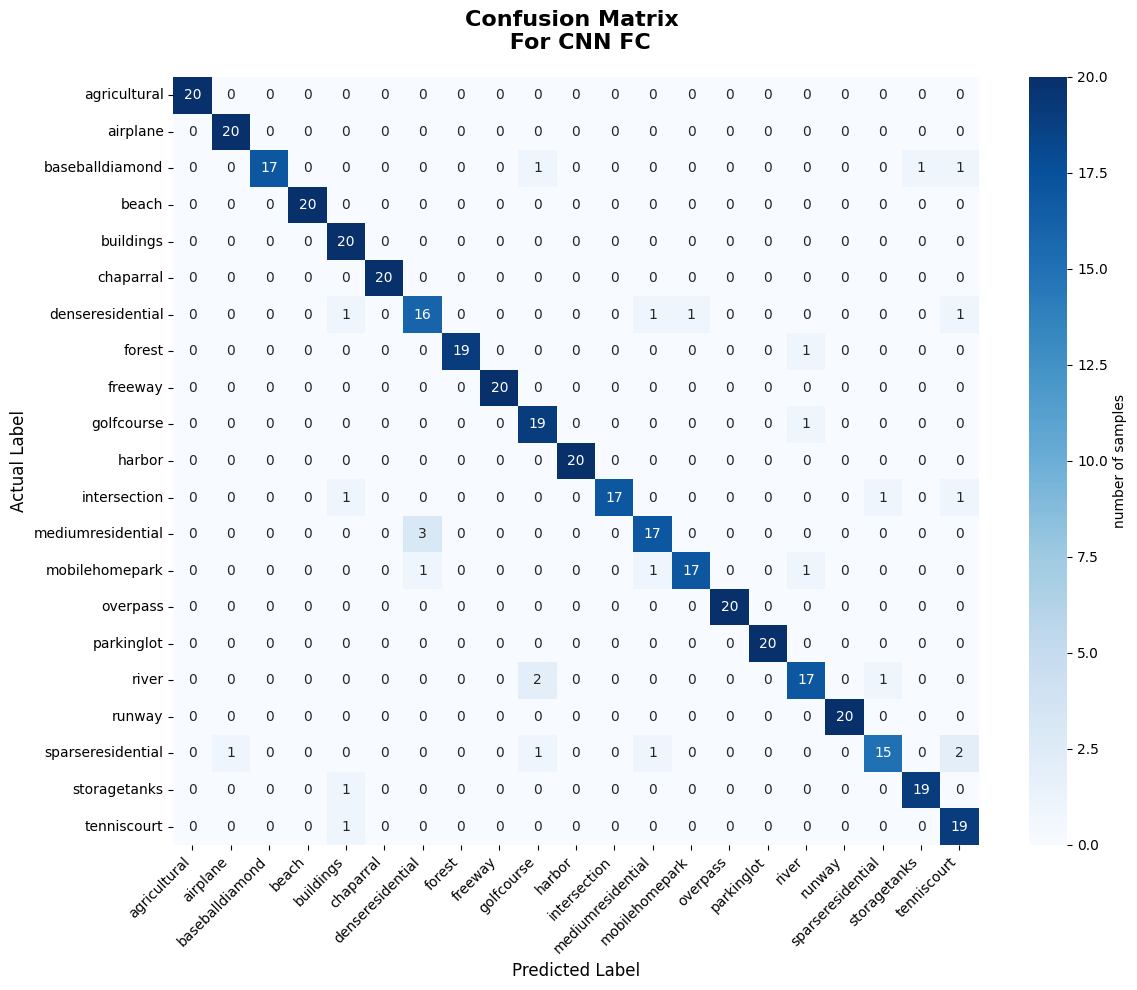

93.33333333333333

In [21]:
checkpoint_path = "/kaggle/working/cnn_fn_checkpoint/cnn_mlp_stateful_best.pth"
evaluate_model(trainer, checkpoint_path, val_loader, device, dataset, model_name="CNN FC")

In [22]:
model = XceptionMLP(
    num_classes=21,
    dropout_rate=0.4,
    pretrained=False
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
model = model.to(device)
model.device = device
optimizer = optim.Adagrad(
    model.mlp.parameters(),
    lr=0.01
)

criterion = nn.CrossEntropyLoss()
criterion = criterion.to(device)

trainer = StatefulCNNMLPTrainer(
    model=model,
    optimizer=optimizer,
    criterion=criterion,
    train_loader=train_combined_loader,
    val_loader=val_loader,
    checkpoint_dir="/kaggle/working/cnn_mlp_checkpoint",
    save_every=5
)


training_results_second = trainer.train(
    num_epochs=50,
    resume_from=None
)

/usr/local/lib/python3.11/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Missing keys: []
Unexpected keys: ['fc.weight', 'fc.bias']
Using device: cuda
Stateful Trainer initialized
Checkpoint directory: /kaggle/working/cnn_mlp_checkpoint
Starting training from epoch 0/50
BEST MODEL SAVED: /kaggle/working/cnn_mlp_checkpoint/cnn_mlp_stateful_best.pth
Epoch   1/50:
  Train Loss: 3.4305 | Train Acc: 37.56%
  Val   Loss: 1.7050 | Val Acc: 69.52%
  Best Val Acc: 69.52%
----------------------------------------------------------------------
BEST MODEL SAVED: /kaggle/working/cnn_mlp_checkpoint/cnn_mlp_stateful_best.pth
Epoch   2/50:
  Train Loss: 1.4668 | Train Acc: 71.57%
  Val   Loss: 1.1801 | Val Acc: 83.81%
  Best Val Acc: 83.81%
----------------------------------------------------------------------
BEST MODEL SAVED: /kaggle/working/cnn_mlp_checkpoint/cnn_mlp_stateful_best.pth
Epoch   3/50:
  Train Loss: 1.1226 | Train Acc: 79.32%
  Val   Loss: 0.9505 | Val Acc: 85.00%
  Best Val Acc: 85.00%
----------------------------------------------------------------------
B

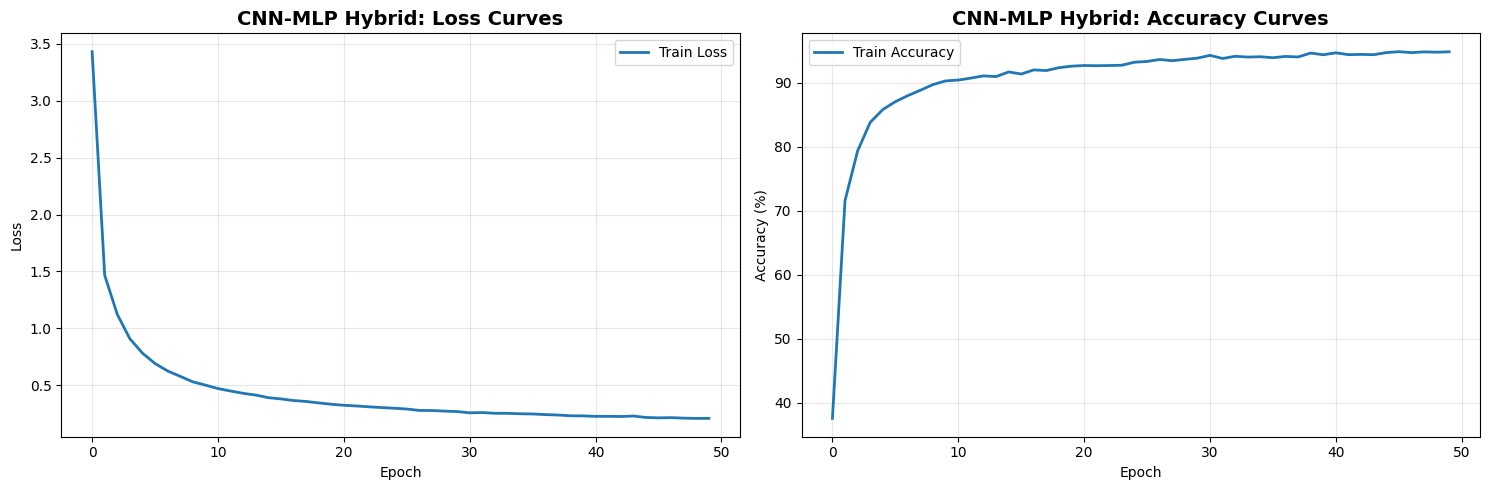

Training completed!
Best validation accuracy: 93.81%


In [23]:
train_losses2 = training_results_second['train_losses']
train_accs2 = training_results_second['train_accs']
val_losses2 = training_results_second['val_losses']
val_accs2 = training_results_second['val_accs']
best_val_acc2 = training_results_second['best_val_acc']

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses2, label='Train Loss', linewidth=2)
# plt.plot(val_losses2, label='Validation Loss', linewidth=2)
plt.title('CNN-MLP Hybrid: Loss Curves', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(train_accs2, label='Train Accuracy', linewidth=2)
# plt.plot(val_accs2, label='Validation Accuracy', linewidth=2)
plt.title('CNN-MLP Hybrid: Accuracy Curves', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Training completed!")
print(f"Best validation accuracy: {best_val_acc2:.2f}%")

In [24]:
import torch
import numpy as np
from sklearn.metrics import classification_report
normalize = transforms.Compose([
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

def evaluate_model(trainer, checkpoint_path, val_loader, device, dataset, model_name="Model"):
    normalize = transforms.Compose([
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    trainer._load_checkpoint(checkpoint_path)
    model = trainer.model
    model.eval()

    all_preds = []
    all_labels = []

    if normalize is None:
        normalize = lambda x: x  

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            images = normalize(images)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    accuracy = 100.0 * (all_preds == all_labels).mean()

    print(f"\n==============================")
    print(f" Evaluation Report for {model_name}")
    print(f" Checkpoint: {checkpoint_path}")
    print(f" Accuracy: {accuracy:.2f}%")
    print(f"==============================\n")

    print(classification_report(all_labels, all_preds, target_names=dataset.classes))
    print(f"==============================\n")
    
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(12, 10))
    
    sns.heatmap(cm, 
                annot=True, 
                fmt='d', 
                cmap='Blues',
                xticklabels=dataset.classes,
                yticklabels=dataset.classes,
                cbar_kws={'label': 'number of samples'})
    
    plt.title(f'Confusion Matrix \n For {model_name}', 
              fontsize=16, fontweight='bold', pad=20)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('Actual Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return accuracy


Checkpoint LOADED from: /kaggle/working/cnn_mlp_checkpoint/cnn_mlp_stateful_best.pth
Resuming from epoch: 44
Best validation accuracy: 93.81%

 Evaluation Report for CNN MLP batch 200
 Checkpoint: /kaggle/working/cnn_mlp_checkpoint/cnn_mlp_stateful_best.pth
 Accuracy: 93.81%

                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        20
         airplane       0.95      1.00      0.98        20
  baseballdiamond       1.00      0.85      0.92        20
            beach       1.00      1.00      1.00        20
        buildings       0.87      1.00      0.93        20
        chaparral       1.00      1.00      1.00        20
 denseresidential       0.80      0.80      0.80        20
           forest       0.91      1.00      0.95        20
          freeway       1.00      1.00      1.00        20
       golfcourse       0.90      0.90      0.90        20
           harbor       1.00      1.00      1.00        20
     intersect

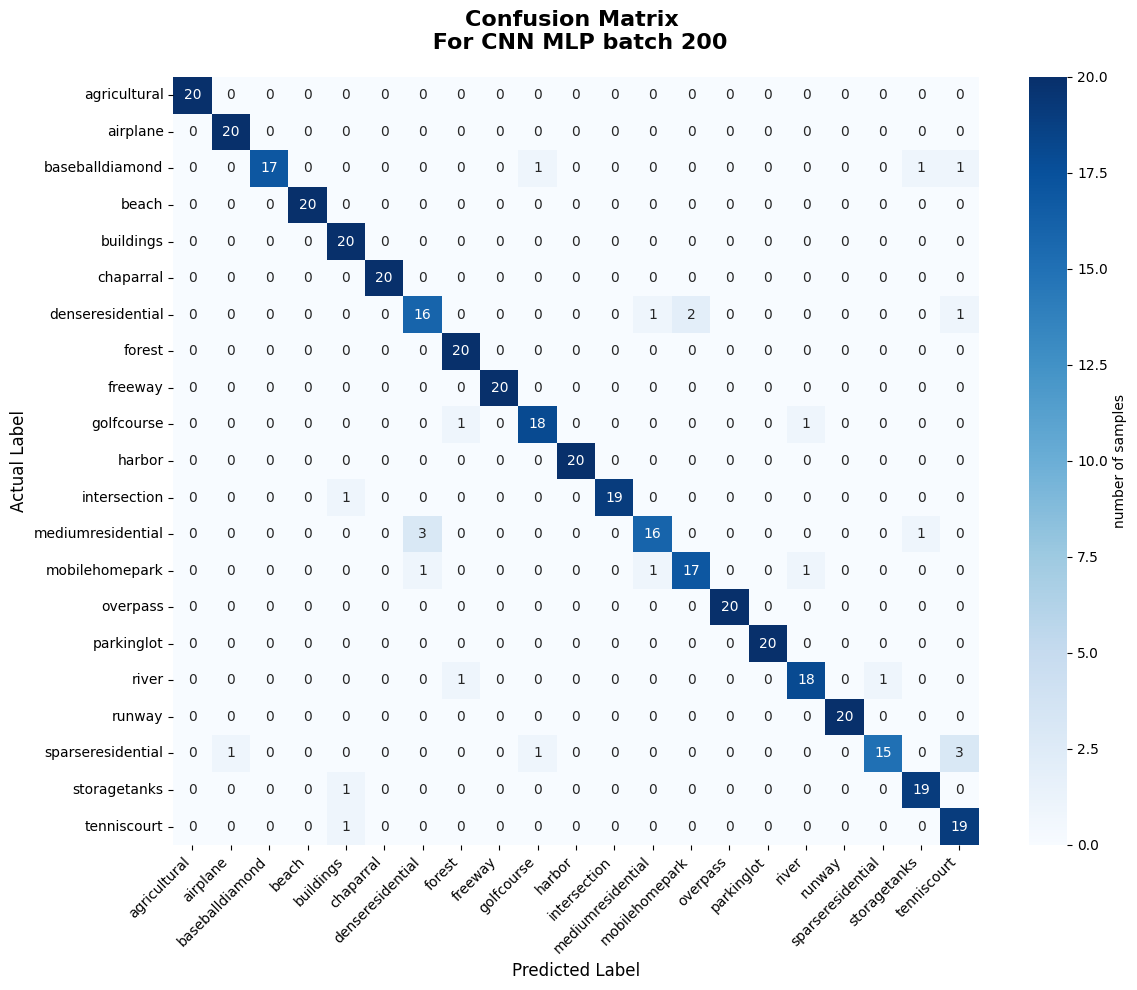

93.80952380952381

In [25]:
# model.load_state_dict(torch.load('best_cnn_mlp_model.pth'))
checkpoint_path = "/kaggle/working/cnn_mlp_checkpoint/cnn_mlp_stateful_best.pth"
evaluate_model(trainer, checkpoint_path, val_loader, device, dataset, model_name="CNN MLP batch 200")



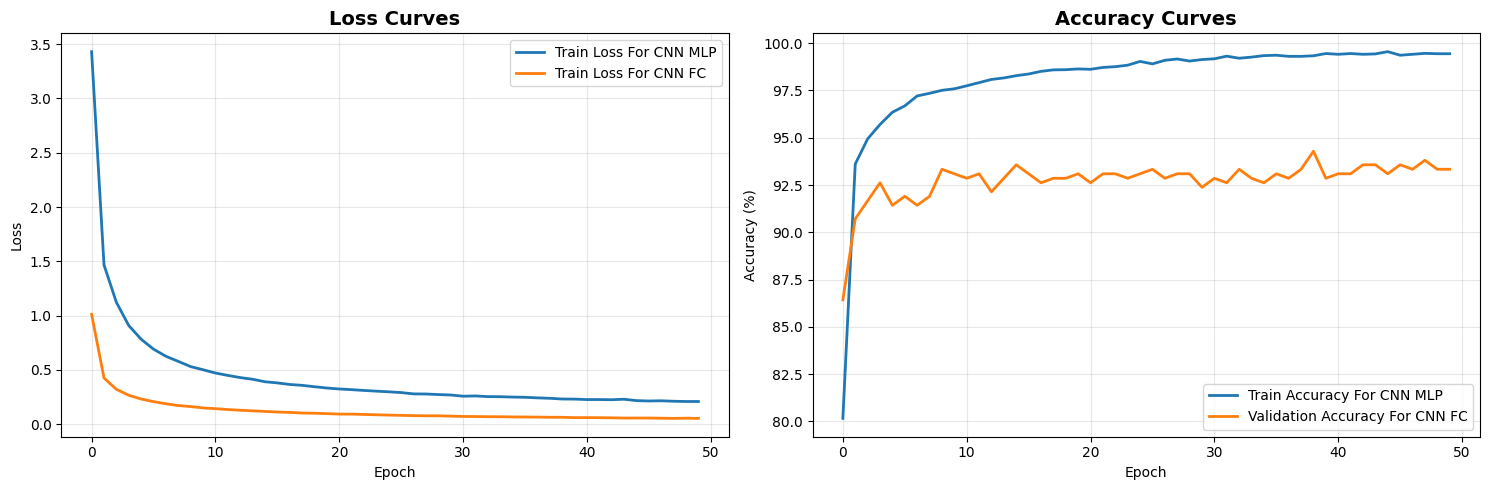

Best validation accuracy for cnn fc: 94.29%


In [26]:

train_losses = training_results['train_losses']
train_accs = training_results['train_accs']
val_losses = training_results['val_losses']
val_accs = training_results['val_accs']
best_val_acc = training_results['best_val_acc']

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses2, label='Train Loss For CNN MLP', linewidth=2)
plt.plot(train_losses, label='Train Loss For CNN FC', linewidth=2)
plt.title('Loss Curves', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy For CNN MLP', linewidth=2)
plt.plot(val_accs, label='Validation Accuracy For CNN FC', linewidth=2)
plt.title('Accuracy Curves', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Best validation accuracy for cnn fc: {best_val_acc:.2f}%")

# بخش 2-5-1 
## این بخش در فایل q2_3 قرار دارد

# بخش 2-5-2

In [30]:
model = XceptionMLP(
    num_classes=21,
    dropout_rate=0.4,
    pretrained=False
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
model = model.to(device)
model.device = device
optimizer = optim.Adam(
    model.mlp.parameters(),
    lr=0.01
)

criterion = nn.CrossEntropyLoss()
criterion = criterion.to(device)

trainer = StatefulCNNMLPTrainer(
    model=model,
    optimizer=optimizer,
    criterion=criterion,
    train_loader=train_combined_loader,
    val_loader=val_loader,
    checkpoint_dir="/kaggle/working/cnn_mlp_adam_checkpoint",
    save_every=5
)


training_results_second = trainer.train(
    num_epochs=50,
    resume_from=None
)

/usr/local/lib/python3.11/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Missing keys: []
Unexpected keys: ['fc.weight', 'fc.bias']
Using device: cuda
Stateful Trainer initialized
Checkpoint directory: /kaggle/working/cnn_mlp_adam_checkpoint
Starting training from epoch 0/50
BEST MODEL SAVED: /kaggle/working/cnn_mlp_adam_checkpoint/cnn_mlp_stateful_best.pth
Epoch   1/50:
  Train Loss: 6.4453 | Train Acc: 31.47%
  Val   Loss: 0.8715 | Val Acc: 75.71%
  Best Val Acc: 75.71%
----------------------------------------------------------------------
BEST MODEL SAVED: /kaggle/working/cnn_mlp_adam_checkpoint/cnn_mlp_stateful_best.pth
Epoch   2/50:
  Train Loss: 0.5183 | Train Acc: 85.28%
  Val   Loss: 0.4387 | Val Acc: 86.90%
  Best Val Acc: 86.90%
----------------------------------------------------------------------
BEST MODEL SAVED: /kaggle/working/cnn_mlp_adam_checkpoint/cnn_mlp_stateful_best.pth
Epoch   3/50:
  Train Loss: 0.3261 | Train Acc: 91.04%
  Val   Loss: 0.3446 | Val Acc: 90.71%
  Best Val Acc: 90.71%
----------------------------------------------------

Checkpoint LOADED from: /kaggle/working/cnn_mlp_adam_checkpoint/cnn_mlp_stateful_best.pth
Resuming from epoch: 33
Best validation accuracy: 95.24%

 Evaluation Report for CNN MLP WITH Adam
 Checkpoint: /kaggle/working/cnn_mlp_adam_checkpoint/cnn_mlp_stateful_best.pth
 Accuracy: 95.00%

                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        20
         airplane       1.00      1.00      1.00        20
  baseballdiamond       1.00      0.90      0.95        20
            beach       1.00      1.00      1.00        20
        buildings       0.79      0.95      0.86        20
        chaparral       1.00      1.00      1.00        20
 denseresidential       0.85      0.85      0.85        20
           forest       0.95      1.00      0.98        20
          freeway       1.00      1.00      1.00        20
       golfcourse       0.90      0.95      0.93        20
           harbor       1.00      1.00      1.00        20
    

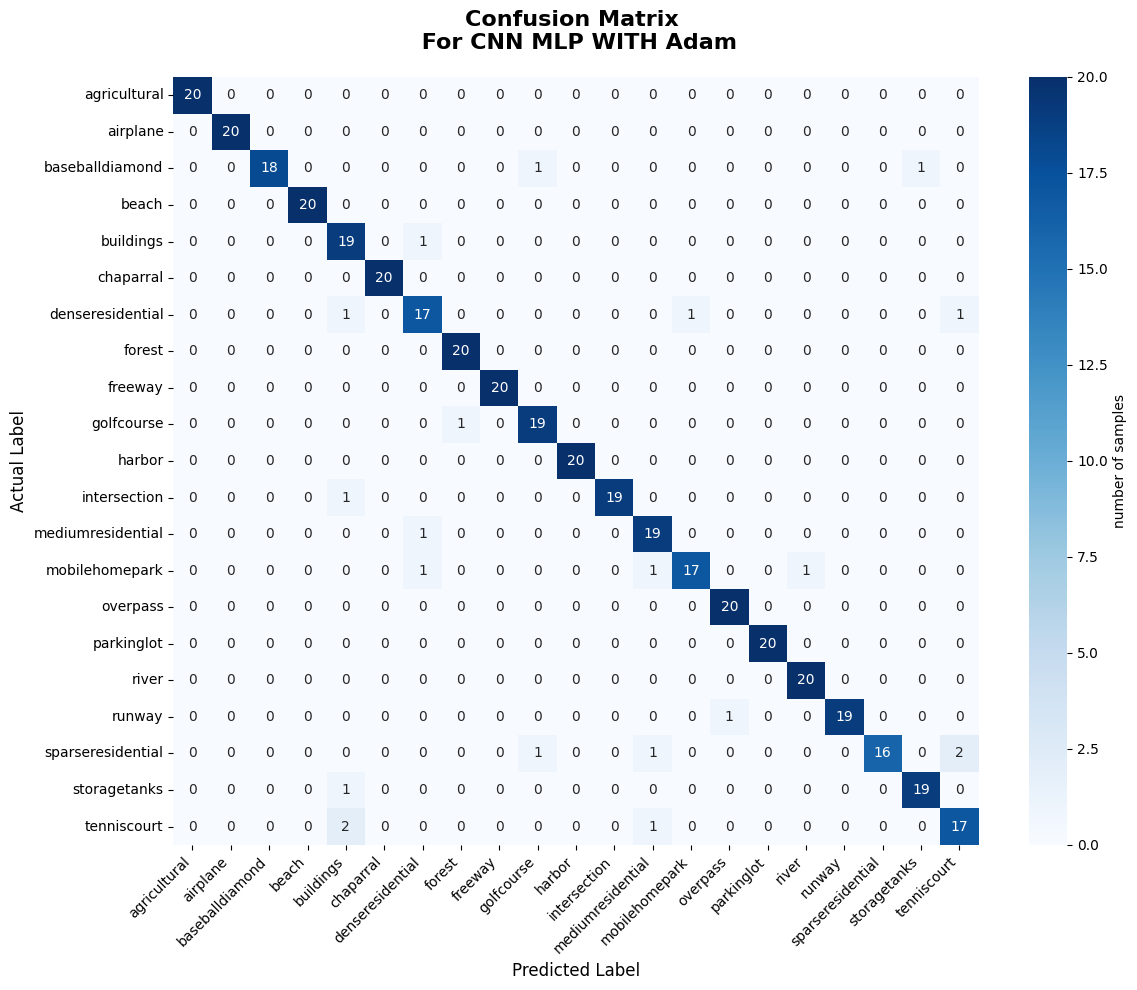

95.0

In [31]:
checkpoint_path = "/kaggle/working/cnn_mlp_adam_checkpoint/cnn_mlp_stateful_best.pth"
evaluate_model(trainer, checkpoint_path, val_loader, device, dataset, model_name="CNN MLP WITH Adam")

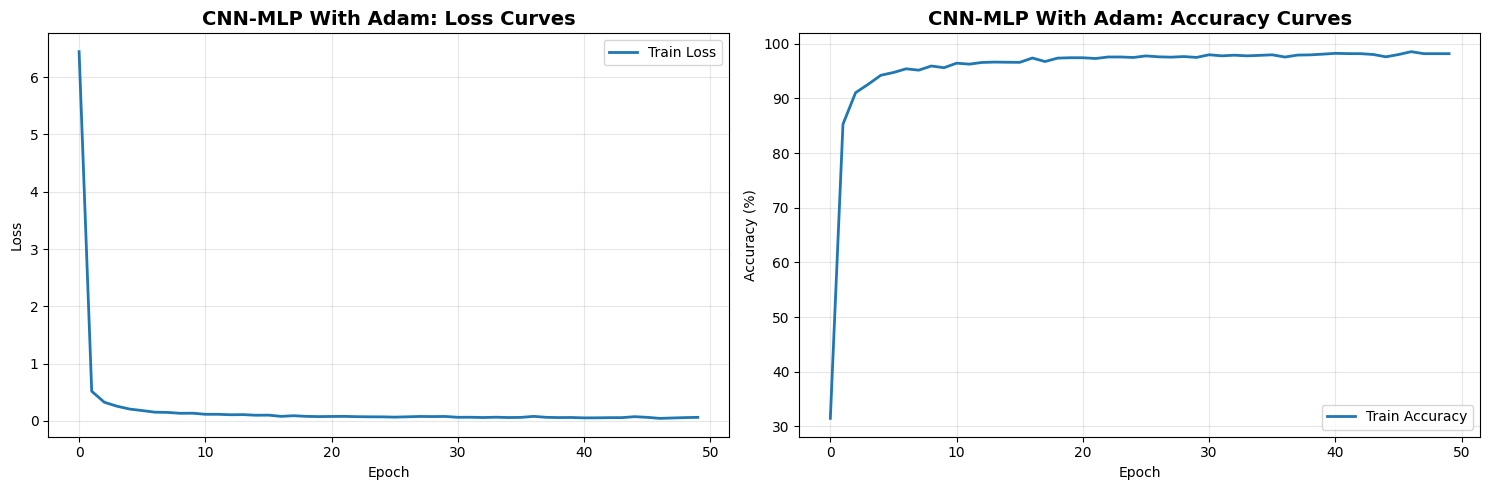

Training completed!
Best validation accuracy: 95.24%


In [32]:
train_losses2 = training_results_second['train_losses']
train_accs2 = training_results_second['train_accs']
val_losses2 = training_results_second['val_losses']
val_accs2 = training_results_second['val_accs']
best_val_acc2 = training_results_second['best_val_acc']

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses2, label='Train Loss', linewidth=2)
# plt.plot(val_losses2, label='Validation Loss', linewidth=2)
plt.title('CNN-MLP With Adam: Loss Curves', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(train_accs2, label='Train Accuracy', linewidth=2)
# plt.plot(val_accs2, label='Validation Accuracy', linewidth=2)
plt.title('CNN-MLP With Adam: Accuracy Curves', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Training completed!")
print(f"Best validation accuracy: {best_val_acc2:.2f}%")